# 04 Off-target (seed) analysis: GSE114273 (siPARP1 / siPARP2 in LNCaP)

**Purpose:** test whether genes with a 3'UTR site matching an siRNA's guide-strand seed are preferentially downregulated after treatment with that siRNA (miRNA-like off-targeting), and list candidate off-target genes.

**Inputs** (`data/datasets/GSE114273/processed/`)
- `GSE114273_seed_gene.tsv`: per gene, site counts / presence / `best_site` for each siRNA (notebook 02)
- `GSE114273_<siRNA>_DGE_results.tsv` (×4): DESeq2 results per siRNA vs siNC (notebook 03)
- `GSE114273_counts_norm.tsv`: DESeq2-normalised counts, for the siNC expression filter (notebook 03)
- `GSE114273_gene_mapping_protein_coding.tsv`: gene symbols, for step 9 (notebook 01)
- `data/reference/processed/human_3UTRs_clean.tsv.gz`: 3'UTR lengths (TargetScan 7), for step 8

**Outputs**
- `processed/GSE114273_seed_dge_gene.tsv`: one row per gene (16,638): siNC mean, gene-set flags, per-siRNA log2FC and `best_site`
- `results/GSE114273/tables/`: `GSE114273_seed_stats.tsv`, `GSE114273_specificity_8mer.tsv`, `GSE114273_specificity_anysite.tsv`, `GSE114273_seed_utr_adjusted.tsv`, `GSE114273_candidate_offtargets.tsv`, `GSE114273_candidate_enrichment.tsv`
- `results/GSE114273/figures/`: `GSE114273_seed_CDF_main.png`, `GSE114273_specificity_heatmap.png`, `GSE114273_volcano_candidates.png`

**Steps**
1. Load inputs (all indexed by Ensembl gene ID).
2. Population: genes with a log2FC **and** a 3'UTR record (16,638); genes without a UTR are dropped, not counted as seed-negative.
3. Expression filter on **siNC only**: main = siNC mean ≥ 10 (12,009 genes); sensitivity = lowest 10 % of siNC removed (14,591).
4. Groups per siRNA (`seed_dge_by_sirna`): own-contrast log2FC + own `best_site`; built once, filtered later with `.loc[gene set]`.
5. CDFs and Δ median log2FC: each site group (8mer, 7mer-m8, 7mer-A1, 6mer) vs `none` (no site of any type).
6. Statistics: Mann–Whitney U (two-sided), prob_lower, Benjamini–Hochberg over 16 tests per gene set; sensitivity table.
7. Specificity matrix: each seed set held fixed and tested in all four contrasts.
8. 3'UTR-length adjustment: median regression `log2FC ~ site group + log10(UTR length)`.
9. Candidate off-targets: strongly down (padj < 0.05, log2FC < −1) with an 8mer/7mer; flagged if also strongly down with the sibling siRNA (same target); enrichment table and volcano plots.

Decisions and reasoning (population, negative group, expression filter) are in `docs/methodology.md`; file details in `data/README.md`.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import mannwhitneyu

print(sys.executable)

/home/piets/sirna_shrna_offtargets/.venv/bin/python


In [2]:
## Inputs: seed annotation (NB 02), DESeq2 results and normalised counts (NB 03)
processed_dir = Path("../../data/datasets/GSE114273/processed")
sirnas = ["siPARP1-A", "siPARP1-B", "siPARP2-A", "siPARP2-B"]

seed_gene = pd.read_csv(processed_dir / "GSE114273_seed_gene.tsv", sep="\t", index_col=0)
dge_by_sirna = {
    sirna: pd.read_csv(processed_dir / f"GSE114273_{sirna}_DGE_results.tsv", sep="\t", index_col=0)
    for sirna in sirnas
}
counts_norm = pd.read_csv(processed_dir / "GSE114273_counts_norm.tsv", sep="\t", index_col=0)

print("seed_gene:", seed_gene.shape)                     # expect (19473, 37)
print("DGE tables:", {s: d.shape for s, d in dge_by_sirna.items()})   # expect (19227, 6) each
print("counts_norm:", counts_norm.shape)                 # expect (19227, 10)

seed_gene: (19473, 37)
DGE tables: {'siPARP1-A': (19227, 6), 'siPARP1-B': (19227, 6), 'siPARP2-A': (19227, 6), 'siPARP2-B': (19227, 6)}
counts_norm: (19227, 10)


In [3]:
## Analysis population: genes with a 3'UTR record (seed_gene) AND a log2FC (all-zero genes have none)
has_lfc = dge_by_sirna[sirnas[0]]["log2FoldChange"].notna()

# One fit -> the same genes have a log2FC in every contrast; check that assumption rather than trust it
assert all(d["log2FoldChange"].notna().equals(has_lfc) for d in dge_by_sirna.values())

population = has_lfc[has_lfc].index.intersection(seed_gene.index)
print("Genes with a log2FC:", has_lfc.sum())           # expect 17240
print("... and a 3'UTR record:", len(population))       # expect 16638

Genes with a log2FC: 17240
... and a 3'UTR record: 16638


In [4]:
## Expression filter on siNC only (CLAUDE.md "Expression filters"; docs/methodology.md)
sinc_mean = counts_norm.loc[population, ["siNC_rep1", "siNC_rep2"]].mean(axis=1)

gene_sets = {
    "main: siNC >= 10": population[sinc_mean >= 10],
    "sensitivity: lowest 10 % of siNC removed": population[sinc_mean > sinc_mean.quantile(0.10)],
}
for name, genes in gene_sets.items():
    print(f"{name}: {len(genes)} genes")
# expect 12009 and 14591

print("siNC cut-off for the lowest 10 %:", round(sinc_mean.quantile(0.10), 2))   # expect ~0.45

main: siNC >= 10: 12009 genes
sensitivity: lowest 10 % of siNC removed: 14591 genes
siNC cut-off for the lowest 10 %: 0.45


In [5]:
## One table per siRNA: its own log2FC (own contrast) + its own seed status, for the whole population
seed_dge_by_sirna = {}

for sirna in sirnas:
    seed_dge_by_sirna[sirna] = pd.DataFrame({
        "log2FoldChange": dge_by_sirna[sirna].loc[population, "log2FoldChange"],
        "baseMean": dge_by_sirna[sirna].loc[population, "baseMean"],
        "best_site": seed_gene.loc[population, f"{sirna}_best_site"],
    })

seed_dge_by_sirna["siPARP1-A"].head(5)

,log2FoldChange,baseMean,best_site
ENSG00000187634,-0.435754,447.519945,none
ENSG00000188976,0.080683,2918.659251,none
ENSG00000187961,0.185674,172.471615,none
ENSG00000187583,0.055421,83.203330,none
ENSG00000187642,-1.027558,18.877986,none


In [6]:
## Genes per best_site group, for each siRNA and each gene set
site_order = ["8mer", "7mer_m8", "7mer_A1", "6mer", "none"]

for set_name, genes in gene_sets.items():
    group_sizes = pd.DataFrame({
        sirna: seed_dge_by_sirna[sirna].loc[genes, "best_site"].value_counts().reindex(site_order)
        for sirna in sirnas
    })
    print(f"\n{set_name}  ({len(genes)} genes)")
    print(group_sizes)


main: siNC >= 10  (12009 genes)
           siPARP1-A  siPARP1-B  siPARP2-A  siPARP2-B
best_site                                            
8mer             917        790        803        480
7mer_m8         1347       1478       1094       1982
7mer_A1         1045       2173       1192        720
6mer            1655       2314       1750       2757
none            7045       5254       7170       6070

sensitivity: lowest 10 % of siNC removed  (14591 genes)
           siPARP1-A  siPARP1-B  siPARP2-A  siPARP2-B
best_site                                            
8mer            1053        912        920        569
7mer_m8         1583       1729       1269       2287
7mer_A1         1207       2508       1410        825
6mer            1953       2719       2091       3283
none            8795       6723       8901       7627


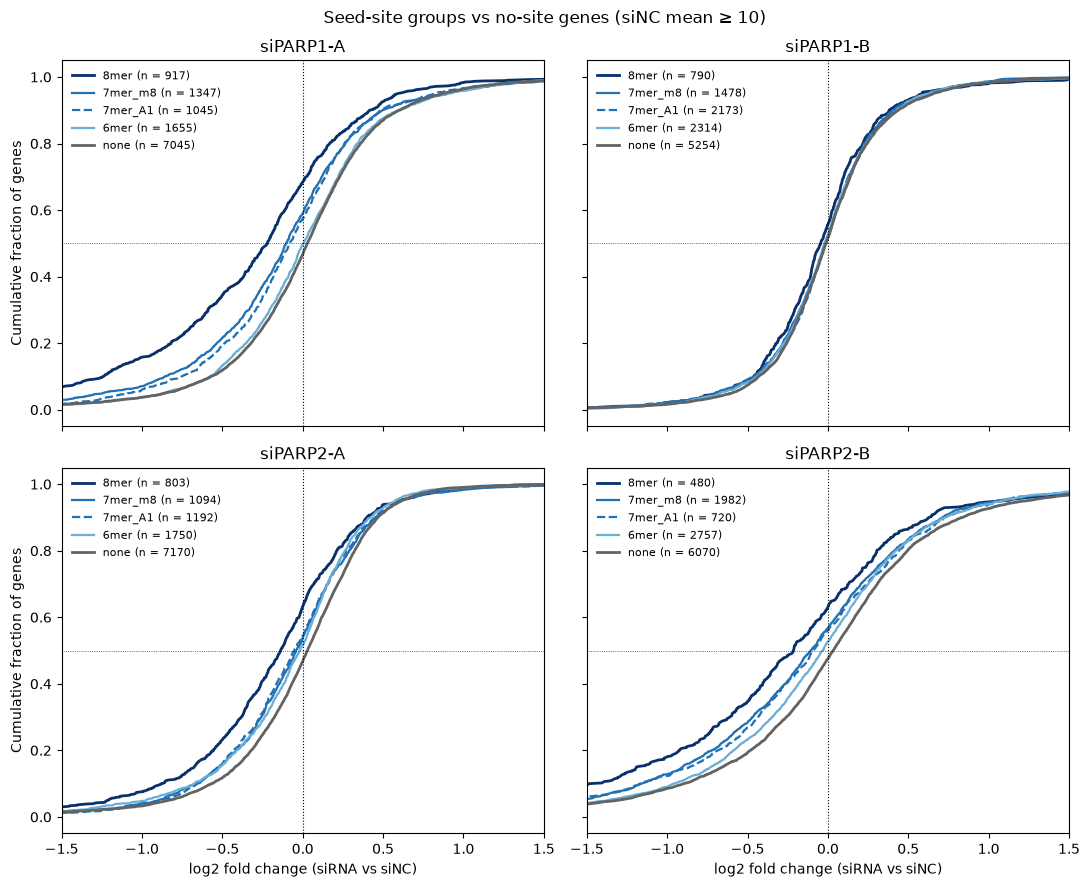

In [7]:
## CDFs of log2FC per best_site group (main gene set)
main_genes = gene_sets["main: siNC >= 10"]

# darker = more stringent site; the two 7mers share a rank, so they differ by line style; 'none' in grey
site_styles = {
    "8mer":    dict(color="#08306b", lw=2),
    "7mer_m8": dict(color="#2171b5", lw=1.6),
    "7mer_A1": dict(color="#2171b5", lw=1.6, ls="--"),
    "6mer":    dict(color="#6baed6", lw=1.6),
    "none":    dict(color="#636363", lw=2),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, sirna in zip(axes.flat, sirnas):
    table = seed_dge_by_sirna[sirna].loc[main_genes]
    for site, style in site_styles.items():
        lfc = np.sort(table.loc[table["best_site"] == site, "log2FoldChange"])
        ax.plot(lfc, np.arange(1, len(lfc) + 1) / len(lfc), label=f"{site} (n = {len(lfc)})", **style)
    ax.axvline(0, color="black", lw=0.8, ls=":")
    ax.axhline(0.5, color="black", lw=0.5, ls=":")
    ax.set_xlim(-1.5, 1.5)
    ax.set_title(sirna)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("log2 fold change (siRNA vs siNC)")
for ax in axes[:, 0]:
    ax.set_ylabel("Cumulative fraction of genes")
fig.suptitle("Seed-site groups vs no-site genes (siNC mean ≥ 10)")
plt.tight_layout()
fig.savefig("../../results/GSE114273/figures/GSE114273_seed_CDF_main.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
## Effect size: median log2FC of each site group minus median of 'none' (negative = repressed)
site_groups = ["8mer", "7mer_m8", "7mer_A1", "6mer"]

delta_median = {}
for sirna in sirnas:
    table = seed_dge_by_sirna[sirna].loc[main_genes]
    median_none = table.loc[table["best_site"] == "none", "log2FoldChange"].median()
    delta_median[sirna] = {
        site: table.loc[table["best_site"] == site, "log2FoldChange"].median() - median_none
        for site in site_groups
    }
delta_median = pd.DataFrame(delta_median)
delta_median.round(3)

,siPARP1-A,siPARP1-B,siPARP2-A,siPARP2-B
8mer,-0.247,-0.032,-0.167,-0.247
7mer_m8,-0.131,0.000,-0.070,-0.140
7mer_A1,-0.109,-0.002,-0.082,-0.122
6mer,-0.022,-0.008,-0.049,-0.068


In [9]:
## Mann-Whitney U (two-sided): each site group vs 'none', per siRNA and gene set
from statsmodels.stats.multitest import multipletests

rows = []
for set_name, genes in gene_sets.items():
    for sirna in sirnas:
        table = seed_dge_by_sirna[sirna].loc[genes]
        lfc_none = table.loc[table["best_site"] == "none", "log2FoldChange"]
        for site in site_groups:
            lfc_site = table.loc[table["best_site"] == site, "log2FoldChange"]
            u_stat, pvalue = mannwhitneyu(lfc_site, lfc_none, alternative="two-sided")
            rows.append({
                "gene_set": set_name,
                "siRNA": sirna,
                "site": site,
                "n_site": len(lfc_site),
                "n_none": len(lfc_none),
                "delta_median": lfc_site.median() - lfc_none.median(),
                "prob_lower": 1 - u_stat / (len(lfc_site) * len(lfc_none)),
                "pvalue": pvalue,
            })

seed_stats = pd.DataFrame(rows)

# Benjamini-Hochberg across the 16 tests (4 siRNAs x 4 site types) within each gene set
seed_stats["padj"] = seed_stats.groupby("gene_set")["pvalue"].transform(
    lambda p: multipletests(p, method="fdr_bh")[1]
)
seed_stats[seed_stats["gene_set"].str.startswith("main")].round({"delta_median": 3, "prob_lower": 3})

,gene_set,siRNA,site,n_site,n_none,delta_median,prob_lower,pvalue,padj
0,main: siNC >= 10,siPARP1-A,8mer,917,7045,-0.247,0.658,7.457204e-55,1.193153e-53
1,main: siNC >= 10,siPARP1-A,7mer_m8,1347,7045,-0.131,0.583,2.526825e-22,1.347640e-21
2,main: siNC >= 10,siPARP1-A,7mer_A1,1045,7045,-0.109,0.569,4.517959e-13,1.204789e-12
3,main: siNC >= 10,siPARP1-A,6mer,1655,7045,-0.022,0.512,1.148007e-01,1.412931e-01
4,main: siNC >= 10,siPARP1-B,8mer,790,5254,-0.032,0.533,3.034152e-03,4.045536e-03
5,main: siNC >= 10,siPARP1-B,7mer_m8,1478,5254,0.000,0.508,3.237340e-01,3.453163e-01
6,main: siNC >= 10,siPARP1-B,7mer_A1,2173,5254,-0.002,0.504,5.660190e-01,5.660190e-01
7,main: siNC >= 10,siPARP1-B,6mer,2314,5254,-0.008,0.507,3.100571e-01,3.453163e-01
8,main: siNC >= 10,siPARP2-A,8mer,803,7170,-0.167,0.607,3.098868e-23,2.479094e-22
9,main: siNC >= 10,siPARP2-A,7mer_m8,1094,7170,-0.070,0.544,2.628931e-06,4.206289e-06


In [10]:
## Sensitivity: does the conclusion change with the permissive filter? (delta median log2FC)
sensitivity = seed_stats.pivot_table(index=["siRNA", "site"], columns="gene_set", values="delta_median")
sensitivity.round(3)

gene_set           main: siNC >= 10  sensitivity: lowest 10 % of siNC removed
siRNA     site                                                               
siPARP1-A 6mer               -0.022                                    -0.025
          7mer_A1            -0.109                                    -0.095
          7mer_m8            -0.131                                    -0.118
          8mer               -0.247                                    -0.243
siPARP1-B 6mer               -0.008                                    -0.011
          7mer_A1            -0.002                                    -0.003
          7mer_m8             0.000                                    -0.007
          8mer               -0.032                                    -0.036
siPARP2-A 6mer               -0.049                                    -0.041
          7mer_A1            -0.082                                    -0.076
          7mer_m8            -0.070                                    -0.051
          8mer               -0.167                                    -0.161
siPARP2-B 6mer               -0.068                                    -0.058
          7mer_A1            -0.122                                    -0.103
          7mer_m8            -0.140                                    -0.115
          8mer               -0.247                                    -0.204

In [11]:
## Specificity: each siRNA's seed set (vs its own 'none' genes), tested in all four contrasts
def specificity_matrix(genes, positive_sites):
    """Delta median log2FC (seed set minus 'none') for every seed set (rows) x contrast (columns).

    genes: gene set to use (one of gene_sets). positive_sites: best_site values counted as seed-positive.
    The gene groups are defined by the ROW siRNA and held fixed; only the log2FC column changes.
    """
    delta = pd.DataFrame(index=sirnas, columns=sirnas, dtype=float)
    for seed_sirna in sirnas:
        best = seed_gene.loc[genes, f"{seed_sirna}_best_site"]
        positive = genes[best.isin(positive_sites)]
        negative = genes[best == "none"]
        for contrast in sirnas:
            lfc = dge_by_sirna[contrast]["log2FoldChange"]
            delta.loc[seed_sirna, contrast] = lfc[positive].median() - lfc[negative].median()
    delta.index.name = "seed set"
    delta.columns.name = "contrast"
    return delta

spec_8mer = specificity_matrix(main_genes, ["8mer"])
spec_any = specificity_matrix(main_genes, site_groups)      # any site type
spec_8mer.round(3)

contrast,siPARP1-A,siPARP1-B,siPARP2-A,siPARP2-B
seed set,,,,
siPARP1-A,-0.247,0.002,-0.030,-0.057
siPARP1-B,-0.021,-0.032,-0.046,0.013
siPARP2-A,-0.013,0.010,-0.167,-0.006
siPARP2-B,-0.049,-0.003,-0.040,-0.247


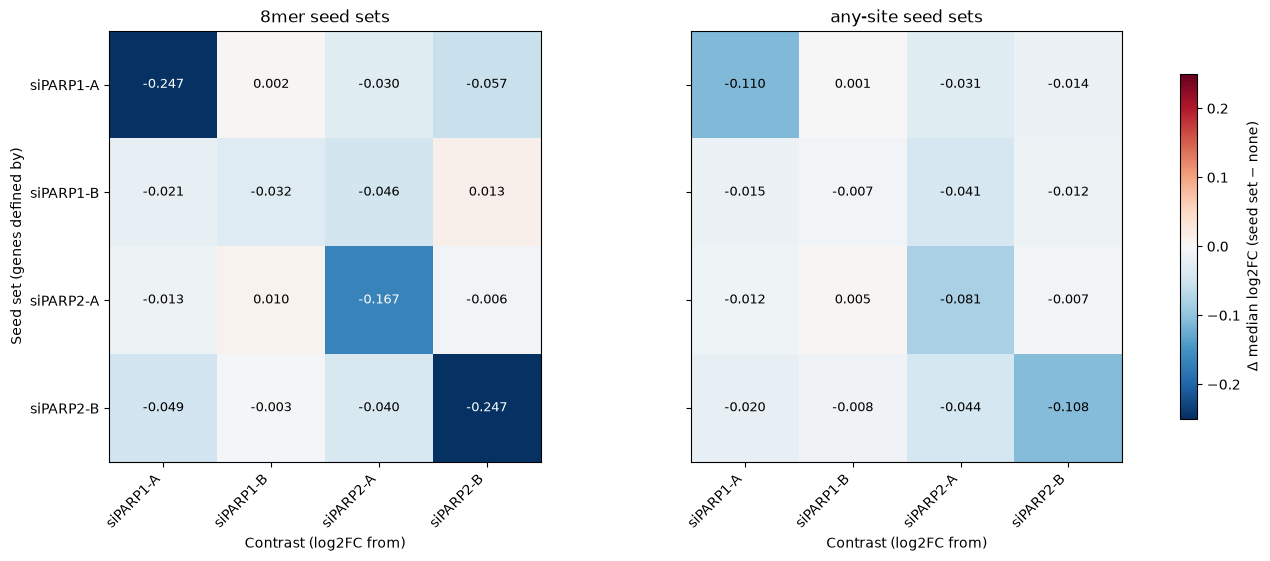

In [12]:
## Heatmap: diverging colours centred on 0 (blue = lower in that contrast, red = higher)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
limit = 0.25
for ax, (title, matrix) in zip(axes, [("8mer seed sets", spec_8mer), ("any-site seed sets", spec_any)]):
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(sirnas)), sirnas, rotation=45, ha="right")
    ax.set_yticks(range(len(sirnas)), sirnas)
    ax.set_xlabel("Contrast (log2FC from)")
    ax.set_title(title)
    for i in range(len(sirnas)):
        for j in range(len(sirnas)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(value) > 0.6 * limit else "black")
axes[0].set_ylabel("Seed set (genes defined by)")
axes[1].tick_params(labelleft=False)          # same rows as the left panel; no need to repeat
fig.colorbar(im, ax=axes, label="Δ median log2FC (seed set − none)", shrink=0.8)
fig.savefig("../../results/GSE114273/figures/GSE114273_specificity_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
## Save: gene-level analysis table (processed data) and result tables (results/)
tables_dir = Path("../../results/GSE114273/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

# Gene-level table: everything needed to rebuild any group, filter or plot
seed_dge_gene = pd.DataFrame({"siNC_mean": sinc_mean})
seed_dge_gene["in_main"] = seed_dge_gene.index.isin(gene_sets["main: siNC >= 10"])
seed_dge_gene["in_sensitivity"] = seed_dge_gene.index.isin(gene_sets["sensitivity: lowest 10 % of siNC removed"])
for sirna in sirnas:
    seed_dge_gene[f"{sirna}_log2FoldChange"] = seed_dge_by_sirna[sirna]["log2FoldChange"]
    seed_dge_gene[f"{sirna}_best_site"] = seed_dge_by_sirna[sirna]["best_site"]
seed_dge_gene.index.name = "EnsemblGeneID"
seed_dge_gene.to_csv(processed_dir / "GSE114273_seed_dge_gene.tsv", sep="\t")

seed_stats.to_csv(tables_dir / "GSE114273_seed_stats.tsv", sep="\t", index=False)
spec_8mer.to_csv(tables_dir / "GSE114273_specificity_8mer.tsv", sep="\t")
spec_any.to_csv(tables_dir / "GSE114273_specificity_anysite.tsv", sep="\t")

print("seed_dge_gene:", seed_dge_gene.shape)       # expect (16638, 11)
print("in_main:", seed_dge_gene["in_main"].sum(), "| in_sensitivity:", seed_dge_gene["in_sensitivity"].sum())   # 12009 | 14591
print("seed_stats:", seed_stats.shape)             # expect (32, 9)

seed_dge_gene: (16638, 11)
in_main: 12009 | in_sensitivity: 14591
seed_stats: (32, 9)


In [14]:
## 3'UTR length per gene = longest annotated isoform (consistent with the 'any isoform' max rule in NB 02)
utr_tx = pd.read_csv("../../data/reference/processed/human_3UTRs_clean.tsv.gz", sep="\t",
                     usecols=["gene_id_clean", "utr_length"])
utr_length_gene = utr_tx.groupby("gene_id_clean")["utr_length"].max()
log10_utr = np.log10(utr_length_gene.reindex(main_genes))
print("Missing UTR length:", log10_utr.isna().sum())    # expect 0

Missing UTR length: 0


In [15]:
## Median regression: log2FC ~ site group (+ log10 UTR length); 'none' is the reference group
import statsmodels.formula.api as smf

rows = []
for sirna in sirnas:
    data = pd.DataFrame({
        "lfc": seed_dge_by_sirna[sirna].loc[main_genes, "log2FoldChange"],
        "site": seed_dge_by_sirna[sirna].loc[main_genes, "best_site"],
        "log10_utr": log10_utr,
    })
    models = {"unadjusted": "lfc ~ C(site, Treatment('none'))",
              "UTR-adjusted": "lfc ~ C(site, Treatment('none')) + log10_utr"}
    for model, formula in models.items():
        fit = smf.quantreg(formula, data).fit(q=0.5)
        ci = fit.conf_int()
        for site in site_groups:
            term = f"C(site, Treatment('none'))[T.{site}]"
            rows.append({"siRNA": sirna, "site": site, "model": model,
                         "coef": fit.params[term], "ci_low": ci.loc[term, 0], "ci_high": ci.loc[term, 1]})

utr_adjusted = pd.DataFrame(rows)
utr_adjusted.pivot_table(index=["siRNA", "site"], columns="model", values="coef").round(3)

model              UTR-adjusted  unadjusted
siRNA     site                             
siPARP1-A 6mer           -0.047      -0.022
          7mer_A1        -0.129      -0.109
          7mer_m8        -0.158      -0.131
          8mer           -0.282      -0.247
siPARP1-B 6mer           -0.005      -0.008
          7mer_A1         0.000      -0.002
          7mer_m8         0.004       0.000
          8mer           -0.029      -0.032
siPARP2-A 6mer           -0.024      -0.049
          7mer_A1        -0.049      -0.082
          7mer_m8        -0.040      -0.071
          8mer           -0.139      -0.167
siPARP2-B 6mer           -0.075      -0.068
          7mer_A1        -0.133      -0.123
          7mer_m8        -0.155      -0.140
          8mer           -0.262      -0.247

In [16]:
utr_adjusted.to_csv(tables_dir / "GSE114273_seed_utr_adjusted.tsv", sep="\t", index=False)

In [17]:
## Step 9: candidate off-targets = strongly down (padj < 0.05 AND log2FC < -1) WITH an 8mer/7mer for that siRNA.
## Sibling check: also strongly down with the other siRNA against the same target -> more likely target-loss biology.
padj_cut, lfc_cut = 0.05, -1.0
candidate_sites = ["8mer", "7mer_m8", "7mer_A1"]
targets = {"siPARP1-A": "PARP1", "siPARP1-B": "PARP1", "siPARP2-A": "PARP2", "siPARP2-B": "PARP2"}
symbol = pd.read_csv(processed_dir / "GSE114273_gene_mapping_protein_coding.tsv", sep="\t",
                     index_col="EnsemblGeneID")["Symbol"]

strongly_down = {
    sirna: (dge_by_sirna[sirna].loc[main_genes, "padj"] < padj_cut)
           & (dge_by_sirna[sirna].loc[main_genes, "log2FoldChange"] < lfc_cut)
    for sirna in sirnas
}

rows = []
for sirna in sirnas:
    siblings = [s for s, target in targets.items() if target == targets[sirna] and s != sirna]
    table = seed_dge_by_sirna[sirna].loc[main_genes]
    is_candidate = strongly_down[sirna] & table["best_site"].isin(candidate_sites)
    for gene_id in table.index[is_candidate]:
        rows.append({
            "siRNA": sirna,
            "EnsemblGeneID": gene_id,
            "Symbol": symbol[gene_id],
            "log2FoldChange": table.loc[gene_id, "log2FoldChange"],
            "padj": dge_by_sirna[sirna].loc[gene_id, "padj"],
            "best_site": table.loc[gene_id, "best_site"],
            "n_site_positions": seed_gene.loc[gene_id, f"{sirna}_6mer_count"],
            "down_with_sibling": any(strongly_down[s][gene_id] for s in siblings),
        })
candidates = pd.DataFrame(rows)
candidates.groupby("siRNA")["down_with_sibling"].agg(candidates="size", shared_with_sibling="sum")

,candidates,shared_with_sibling
siRNA,,
siPARP1-A,294,19
siPARP1-B,78,24
siPARP2-A,143,49
siPARP2-B,417,53


In [18]:
## % of 8mer genes vs no-site genes that are strongly down (same thresholds)
enrichment = pd.DataFrame({
    sirna: {
        "pct_8mer_genes_down": strongly_down[sirna][seed_dge_by_sirna[sirna].loc[main_genes, "best_site"] == "8mer"].mean() * 100,
        "pct_nosite_genes_down": strongly_down[sirna][seed_dge_by_sirna[sirna].loc[main_genes, "best_site"] == "none"].mean() * 100,
    }
    for sirna in sirnas
}).T
enrichment["ratio"] = enrichment["pct_8mer_genes_down"] / enrichment["pct_nosite_genes_down"]
enrichment.round(1)

,pct_8mer_genes_down,pct_nosite_genes_down,ratio
siPARP1-A,15.5,3.2,4.8
siPARP1-B,1.6,1.2,1.4
siPARP2-A,7.2,2.8,2.6
siPARP2-B,17.9,8.1,2.2


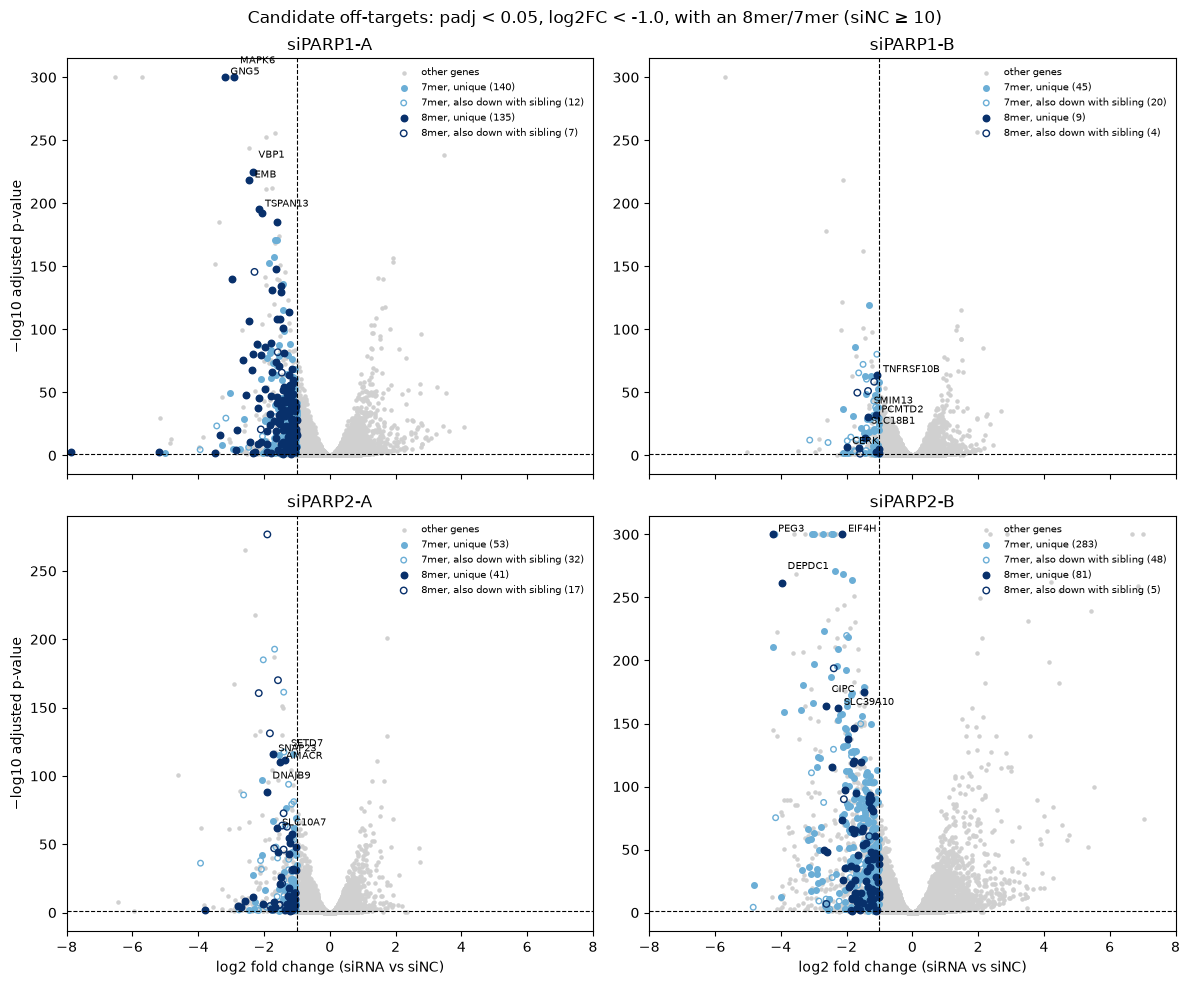

In [19]:
## Volcano per siRNA (main gene set): candidates coloured by site; hollow = also strongly down with the sibling siRNA.
## Labels: top 5 unique 8mer candidates by |log2FC| x -log10(padj). padj below 1e-300 is shown at 300.
site_styles = {"8mer": dict(color="#08306b", s=22), "7mer": dict(color="#6baed6", s=16)}

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)
for ax, sirna in zip(axes.flat, sirnas):
    res = dge_by_sirna[sirna].loc[main_genes].dropna(subset=["padj"])
    neg_log_padj = -np.log10(res["padj"].clip(lower=1e-300))
    cand = candidates[candidates["siRNA"] == sirna].set_index("EnsemblGeneID")

    other = ~res.index.isin(cand.index)
    ax.scatter(res.loc[other, "log2FoldChange"], neg_log_padj[other], s=5, color="#d0d0d0",
               rasterized=True, label="other genes")
    for site_label, sites in [("7mer", ["7mer_m8", "7mer_A1"]), ("8mer", ["8mer"])]:
        style = site_styles[site_label]
        for shared in [False, True]:
            sel = cand[cand["best_site"].isin(sites) & (cand["down_with_sibling"] == shared)]
            ax.scatter(sel["log2FoldChange"], neg_log_padj[sel.index], s=style["s"], linewidths=1,
                       edgecolors=style["color"], facecolors="none" if shared else style["color"],
                       label=f"{site_label}, {'also down with sibling' if shared else 'unique'} ({len(sel)})")

    unique_8mer = cand[(cand["best_site"] == "8mer") & ~cand["down_with_sibling"]].copy()
    unique_8mer["score"] = unique_8mer["log2FoldChange"].abs() * neg_log_padj[unique_8mer.index]
    for k, (gene_id, row) in enumerate(unique_8mer.nlargest(5, "score").iterrows()):
        ax.annotate(row["Symbol"], (row["log2FoldChange"], neg_log_padj[gene_id]),
                    xytext=(4, 2 + 8 * (k % 2)), textcoords="offset points", fontsize=7)

    ax.axvline(lfc_cut, ls="--", lw=0.8, color="black")
    ax.axhline(-np.log10(padj_cut), ls="--", lw=0.8, color="black")
    ax.set_xlim(-8, 8)
    ax.set_title(sirna)
    ax.legend(frameon=False, fontsize=7, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("log2 fold change (siRNA vs siNC)")
for ax in axes[:, 0]:
    ax.set_ylabel("−log10 adjusted p-value")
fig.suptitle(f"Candidate off-targets: padj < {padj_cut}, log2FC < {lfc_cut}, with an 8mer/7mer (siNC ≥ 10)")
plt.tight_layout()
fig.savefig("../../results/GSE114273/figures/GSE114273_volcano_candidates.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
candidates.sort_values(["siRNA", "down_with_sibling", "padj"]).to_csv(
    tables_dir / "GSE114273_candidate_offtargets.tsv", sep="\t", index=False)
enrichment.to_csv(tables_dir / "GSE114273_candidate_enrichment.tsv", sep="\t")
print("Saved:", candidates.shape, enrichment.shape)      # expect (932, 8) (4, 3)

Saved: (932, 8) (4, 3)


## Summary

### Main result
For **siPARP1-A, siPARP2-A and siPARP2-B**, genes with a 3'UTR seed site were preferentially downregulated in that siRNA's own contrast, with a clear gradient by site strength (8mer > 7mers > 6mer). **siPARP1-B** showed no detectable seed-associated shift.

| Δ median log2FC vs `none` (main set) | siPARP1-A | siPARP1-B | siPARP2-A | siPARP2-B |
|---|---|---|---|---|
| 8mer | −0.247 | −0.032 | −0.167 | −0.247 |
| 7mer-m8 | −0.131 | 0.000 | −0.070 | −0.140 |
| 7mer-A1 | −0.109 | −0.002 | −0.082 | −0.122 |
| 6mer | −0.022 | −0.008 | −0.049 | −0.068 |

- 8mer prob_lower 0.66 / 0.53 / 0.61 / 0.61 (0.5 = no difference); a shift of −0.25 ≈ 16 % lower median expression.
- Shape: the 8mer–none gap is largest in the lower tail (siPARP1-A: −0.67 at the 10th percentile vs −0.19 at the 90th), i.e. a strongly repressed subset rather than a uniform shift, as expected for seed-mediated repression.

### Controls
- **Specificity:** each 8mer seed set is shifted 4–8× more in its own contrast (diagonal −0.25 / −0.17 / −0.25) than in the other contrasts (−0.06 to +0.01).
- **Sensitivity** (lowest 10 % of siNC removed): same signs and order, slightly smaller effects (noise dilution).
- **3'UTR length:** seed genes have ~3.6× longer UTRs than no-site genes, and the siPARP2-A contrast lowers long-UTR genes in general (explains its negative specificity column). After median-regression adjustment the 8mer effects are −0.282, −0.029, −0.139, −0.262: siPARP1-A and siPARP2-B unchanged or stronger; siPARP2-A reduced but still specific.

### Candidate off-targets (padj < 0.05, log2FC < −1, with an 8mer/7mer)

| | siPARP1-A | siPARP1-B | siPARP2-A | siPARP2-B |
|---|---|---|---|---|
| Candidates | 294 | 78 | 143 | 417 |
| … also strongly down with the sibling siRNA | 19 | 24 | 49 | 53 |
| % of 8mer genes strongly down | 15.5 | 1.6 | 7.2 | 17.9 |
| % of no-site genes strongly down | 3.2 | 1.2 | 2.8 | 8.1 |
| Ratio | 4.8× | 1.4× | 2.6× | 2.2× |

- Genes also strongly down with the sibling siRNA (same target, different seed) are more likely target-loss biology, e.g. FKBP5 with both PARP2 siRNAs (AR target, as in the paper); they are kept but flagged.
- Top unique 8mer candidates: siPARP1-A GNG5, MAPK6, EMB, VBP1, TSPAN13; siPARP2-B PEG3, DEPDC1, EIF4H, CIPC, SLC39A10.
- These are **candidates**, not confirmed off-targets.

### Interpretation
The pattern (site-type gradient, seed specificity, robustness to filter and UTR length, repressed subset, enrichment of seed genes among strongly downregulated genes) is consistent with **miRNA-like off-targeting** by three of the four siRNAs. It is an association at the population level, not proof that a particular gene is an off-target; causal proof needs seed-mutant siRNAs, reporter assays or AGO binding data.

### Limitations
- n = 2 per condition (conservative effect estimates); p-values anti-conservative because genes are not independent, so effect sizes are the primary measure.
- One dataset and cell line; siNC sequence unknown; TargetScan 3'UTR isoforms may differ from those expressed in LNCaP.
- Small unexplained off-diagonal values (e.g. siPARP1-B seed set in the siPARP2-B contrast).

Reasoning behind the filter, population and negative group: `docs/methodology.md`.